In [1]:
# charger les positions
import os
import requests
import geopandas as gpd
import pandas as pd
from datetime import datetime, timedelta
import json

# Exemple : récupérer les positions de véhicules
API_KEY = "9bc1c4ac06a0a97629446a1c0b384aeceef9566ef30f4e8c521deafe30b5dce5b696d15d8adb1d2b7a767a517459187c3ac72f9fedb76fd23988a216805e72e9"

# Deux variantes à tester : param apiKey dans l'URL, ou Authorization header
url_param = f"https://api.mobilitytwin.brussels/stib/vehicle-position?apiKey={API_KEY}"
url_header = "https://api.mobilitytwin.brussels/stib/vehicle-position"

def test_request(url, use_header=False, timeout=10):
    try:
        headers = {"Authorization": f"Bearer {API_KEY}"} if use_header else None
        r = requests.get(url, headers=headers, timeout=timeout)
    except Exception as e:
        print(f"Request error for {url} (header={use_header}):", e)
        return None, None
    print(f"URL: {url}  (header={use_header}) -> status {r.status_code}")
    text = r.text or ""
    print("Response preview:", text[:2000])
    if r.status_code == 200:
        try:
            data = r.json()
            print("JSON parsed. Top-level keys:", list(data.keys()) if isinstance(data, dict) else type(data))
            return r, data
        except Exception as e:
            print("Failed to parse JSON:", e)
            return r, None
    else:
        return r, None

# Tester les deux variantes
resp1, data1 = test_request(url_param, use_header=False)
resp2, data2 = test_request(url_header, use_header=True)

# Choisir la première réponse JSON valide
data = None
if data1 is not None:
    data = data1
    print("Using data from url with apiKey param")
elif data2 is not None:
    data = data2
    print("Using data from url with Authorization header")
else:
    print("Aucune réponse JSON valide obtenue. Arrêt des étapes suivantes.")

# Convertir GeoJSON en GeoDataFrame si possible
vehicles = None
if data is not None:
    if isinstance(data, dict) and "features" in data:
        try:
            vehicles = gpd.GeoDataFrame.from_features(data["features"])
            print("vehicles GeoDataFrame created, columns:", vehicles.columns.tolist())
            print(vehicles.head())
        except Exception as e:
            print("Erreur lors de la création de GeoDataFrame:", e)
    else:
        print("Le JSON ne contient pas 'features' ou n'est pas au format attendu. type(data):", type(data))

# B - Vérifier l'existence des fichiers locaux (shapefiles, GTFS)
paths = ["stib_shapefile.zip", "stib_stops.shp", "GTFS/trips.txt", "GTFS/stop_times.txt", "GTFS/routes.txt"]
print('\nLocal files check:')
for p in paths:
    exists = os.path.exists(p)
    size = os.path.getsize(p) if exists and os.path.isfile(p) else None
    print(f" - {p}: exists={exists}, size={size}")

# C - Construire 'actual' à partir de 'vehicles' si possible
actual = None
if vehicles is not None:
    actual = vehicles.copy()
    # Trouver colonne temps candidate
    time_cols = [c for c in actual.columns if 'time' in c.lower() or 'timestamp' in c.lower() or 'date' in c.lower()]
    print("Candidate time columns in vehicles:", time_cols)
    if time_cols:
        col = time_cols[0]
        try:
            actual['timestamp'] = pd.to_datetime(actual[col], errors='coerce')
            print("Parsed timestamp column from", col)
        except Exception as e:
            print("Erreur parsing time column:", e)
    else:
        print("Aucune colonne de temps évidente trouvée dans 'vehicles'. Voici les colonnes:", actual.columns.tolist())

    # Vérifier présence de trip_id/stop_id/line_id
    for key in ['trip_id','stop_id','line_id','route_id','vehicle_id']:
        if key in actual.columns:
            print(f"Found column {key} in actual")

    # Aperçu minimal
    print("actual preview:")
    print(actual.head())

# Si 'actual' n'est pas construit, afficher recommandation
if actual is None:
    print("\nJe n'ai pas pu construire `actual`. Si vous avez un fichier local de positions (CSV/GeoJSON), chargez-le et créez `actual` avec au minimum: trip_id, stop_id, timestamp, line_id (ou route_id), arrival_time_actual.")

# Fin du diagnostic
print('\nDiagnostic terminé.')


URL: https://api.mobilitytwin.brussels/stib/vehicle-position?apiKey=9bc1c4ac06a0a97629446a1c0b384aeceef9566ef30f4e8c521deafe30b5dce5b696d15d8adb1d2b7a767a517459187c3ac72f9fedb76fd23988a216805e72e9  (header=False) -> status 401
Response preview: Unauthorized
URL: https://api.mobilitytwin.brussels/stib/vehicle-position  (header=True) -> status 200
Response preview: {"type": "FeatureCollection", "features": [{"id": "b202fd24-54f9-42eb-9e9f-cb81ec47468d", "type": "Feature", "properties": {"id": 424, "pointId": 8111, "lineId": "1", "direction": 1, "distanceFromPoint": 1, "color": "#B5378C", "timestamp": 1763050126.228219, "uuid": "b202fd24-54f9-42eb-9e9f-cb81ec47468d", "distance": 4173.788227315489}, "geometry": {"type": "Point", "coordinates": [4.4182859221993676, 50.84250644421673]}}, {"id": "e2379900-bcf1-4c19-aae0-1b23b2225bb3", "type": "Feature", "properties": {"id": 406, "pointId": 8031, "lineId": "1", "direction": 1, "distanceFromPoint": 0, "color": "#B5378C", "timestamp": 1763050126


📊 ANALYSES ET VISUALISATIONS

📌 DONNÉES DISPONIBLES:
   ✓ Véhicules: 676 positions
   ✓ Colonnes véhicules: ['geometry', 'id', 'pointId', 'lineId', 'direction', 'distanceFromPoint', 'color', 'timestamp', 'uuid', 'distance']
   ✓ Coordonnées:          minx       miny      maxx       maxy
0    4.418286  50.842506  4.418286  50.842506
1    4.362431  50.845629  4.362431  50.845629
2    4.464541  50.841873  4.464541  50.841873
3    4.458719  50.848796  4.458719  50.848796
4    4.340056  50.854968  4.340056  50.854968
..        ...        ...       ...        ...
671  4.397027  50.810251  4.397027  50.810251
672  4.378687  50.829962  4.378687  50.829962
673  4.355896  50.839937  4.355896  50.839937
674  4.350493  50.841607  4.350493  50.841607
675  4.358507  50.841567  4.358507  50.841567

[676 rows x 4 columns]

📍 RÉPARTITION PAR LIGNE:
   Total de lignes: 69
   Véhicules par ligne (top 10):
lineId
95    20
7     20
81    17
5     17
71    17
92    17
9     17
82    16
87    15
46    14
Na

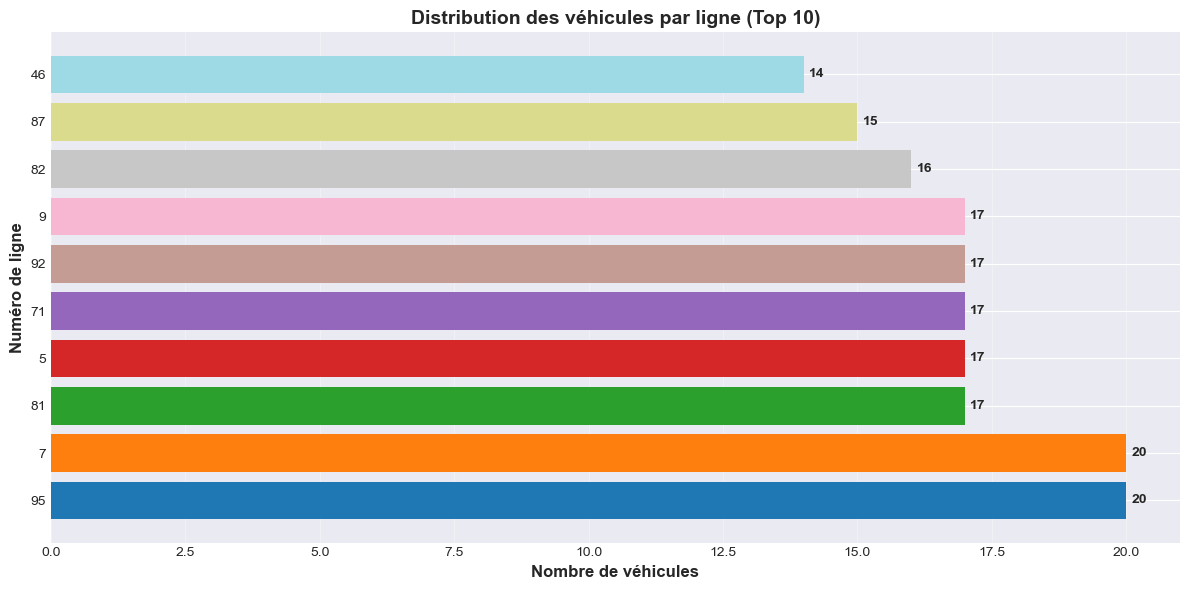


🗺️ ANALYSE GÉOGRAPHIQUE:
   Latitude: [50.7768, 50.9245]
   Longitude: [4.2661, 4.5054]
   ✅ Graphique sauvegardé: /tmp/vehicles_spatial_distribution.png
   ✅ Graphique sauvegardé: /tmp/vehicles_spatial_distribution.png


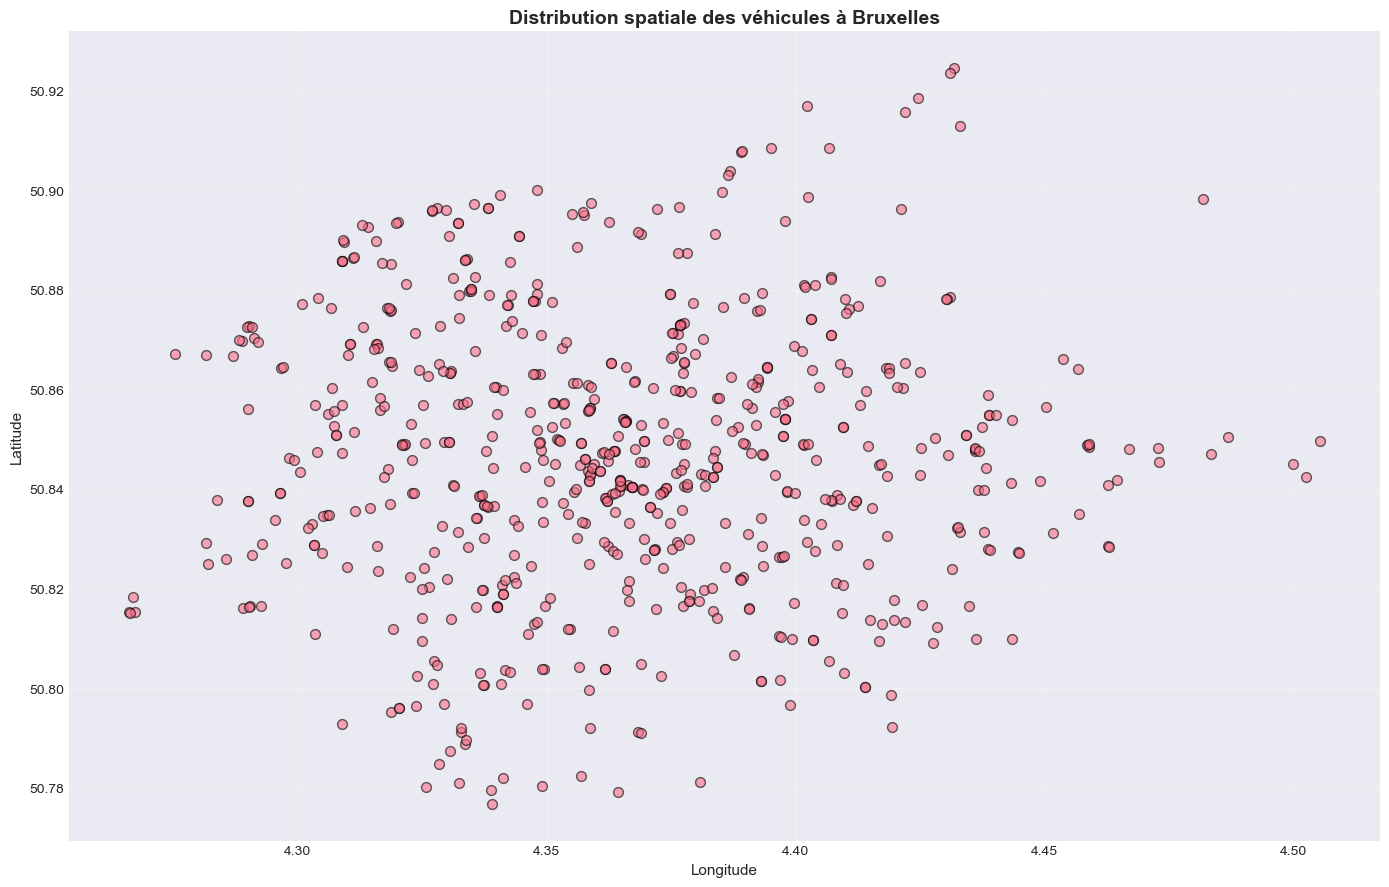


📏 DISTANCE AU PROCHAIN ARRÊT:
count      676.000000
mean      4914.424378
std       3656.742753
min          0.000000
25%       1932.197525
50%       4429.176761
75%       7550.537081
max      18129.774181
Name: distance, dtype: float64
   ✅ Graphique sauvegardé: /tmp/distance_distribution.png
   ✅ Graphique sauvegardé: /tmp/distance_distribution.png


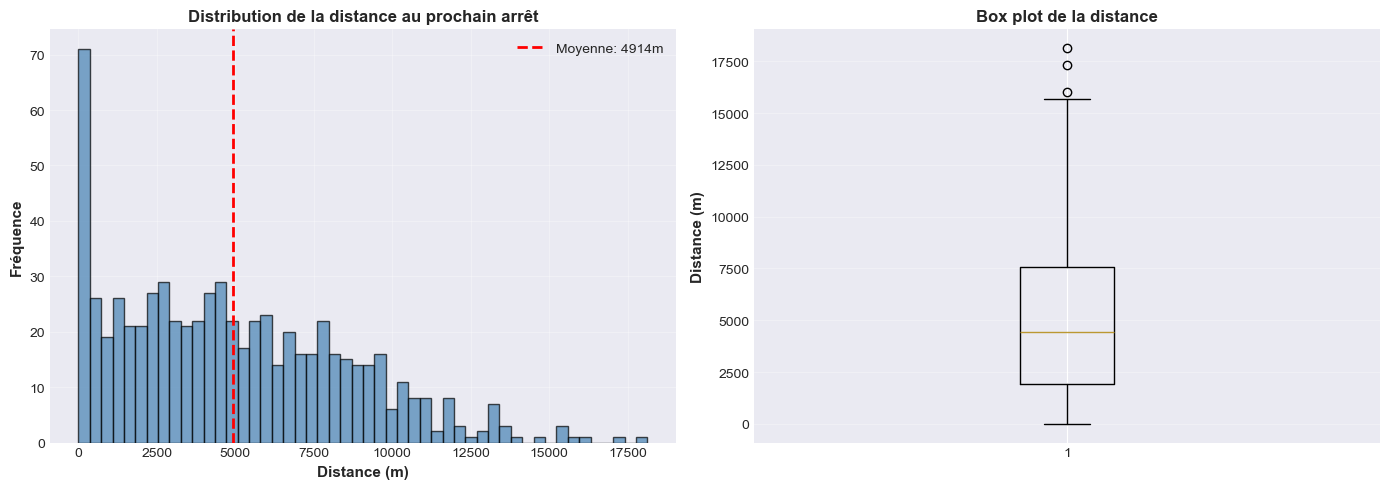


🚌 POSITIONS PAR LIGNE (Top 5):
   ✅ Graphique sauvegardé: /tmp/vehicles_by_line_spatial.png
   ✅ Graphique sauvegardé: /tmp/vehicles_by_line_spatial.png


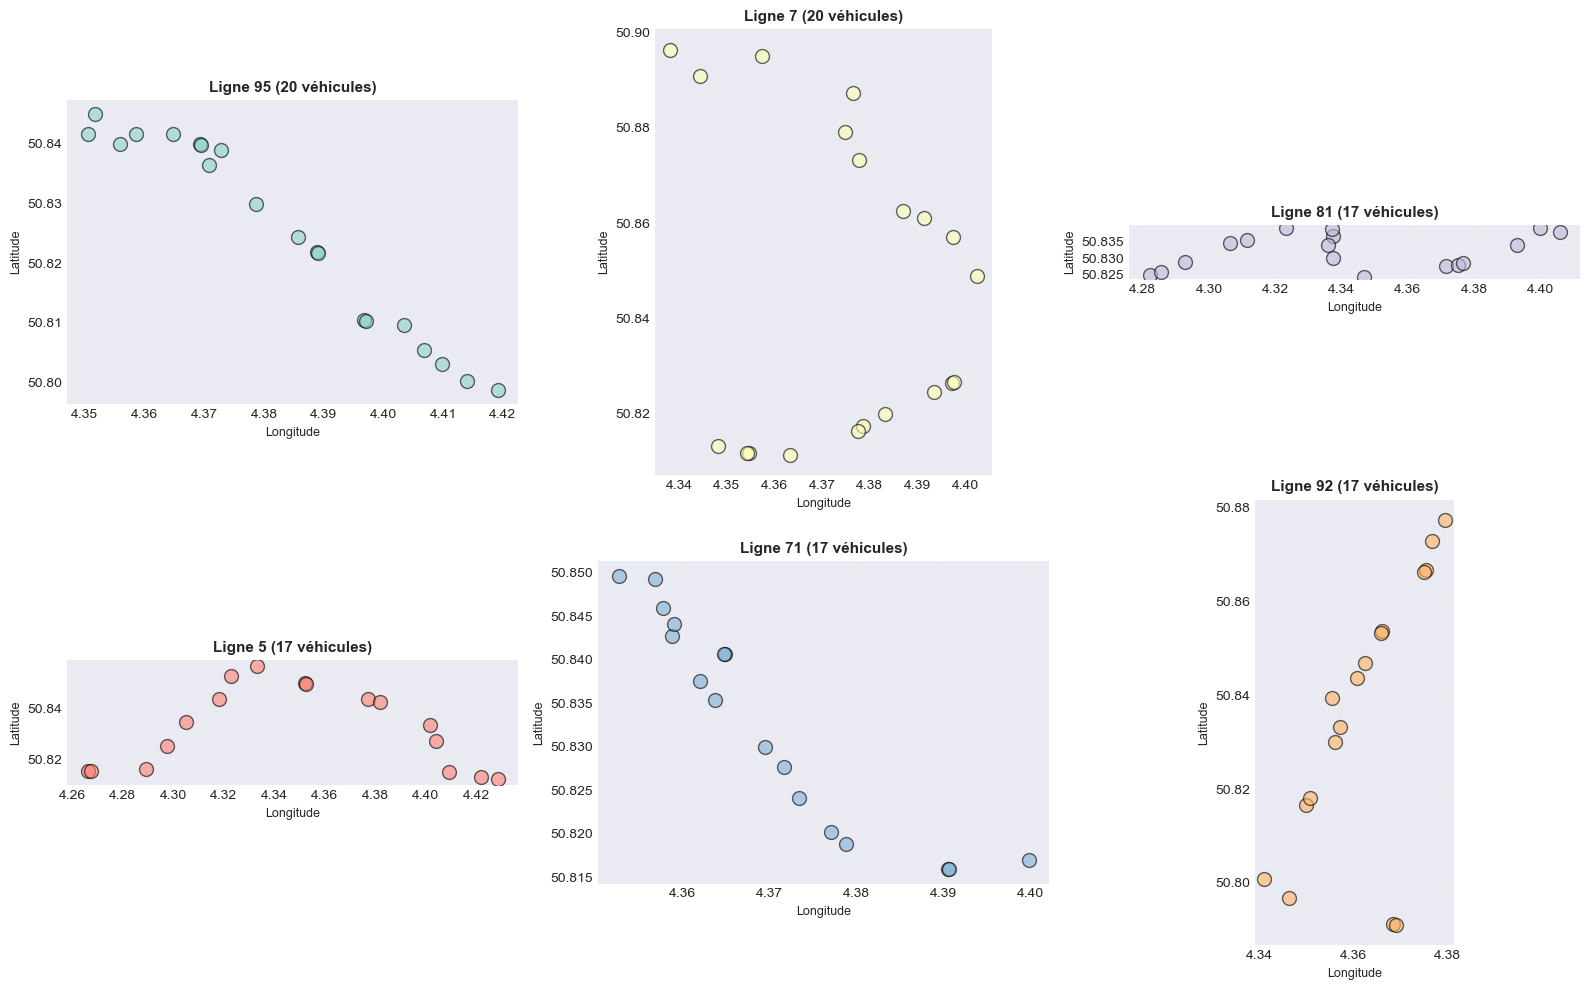


📈 RÉSUMÉ STATISTIQUE:
   Total de véhicules: 676
   Nombre de lignes: 69
   Nombre de points d'arrêt (pointId): 621
   Distance moyenne: 4914.42 m
   Distance médiane: 4429.18 m
   Distance max: 18129.77 m

   CRS (Coordinate Reference System): None
   Type de géométrie: ['Point']

✅ TOUS LES GRAPHIQUES ONT ÉTÉ GÉNÉRÉS AVEC SUCCÈS!


In [3]:

# === GRAPHIQUES ET ANALYSES ===
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print('\n' + '='*70)
print('📊 ANALYSES ET VISUALISATIONS')
print('='*70)

# Configuration du style des graphiques
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# 1. Vérification des données disponibles
print('\n📌 DONNÉES DISPONIBLES:')
print(f"   ✓ Véhicules: {len(vehicles)} positions")
print(f"   ✓ Colonnes véhicules: {vehicles.columns.tolist()}")
print(f"   ✓ Coordonnées: {vehicles.geometry.bounds}")

# 2. Analyse des lignes (lineId)
if 'lineId' in vehicles.columns:
    lines = vehicles['lineId'].value_counts()
    print(f"\n📍 RÉPARTITION PAR LIGNE:")
    print(f"   Total de lignes: {len(lines)}")
    print(f"   Véhicules par ligne (top 10):")
    print(lines.head(10))
    
    # Graphique 1: Distribution des véhicules par ligne (Top 10)
    fig, ax = plt.subplots(figsize=(12, 6))
    top_lines = lines.head(10)
    colors = plt.cm.tab20(np.linspace(0, 1, len(top_lines)))
    ax.barh(top_lines.index.astype(str), top_lines.values, color=colors)
    ax.set_xlabel('Nombre de véhicules', fontsize=12, fontweight='bold')
    ax.set_ylabel('Numéro de ligne', fontsize=12, fontweight='bold')
    ax.set_title('Distribution des véhicules par ligne (Top 10)', fontsize=14, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    for i, v in enumerate(top_lines.values):
        ax.text(v + 0.1, i, str(v), va='center', fontweight='bold')
    plt.tight_layout()
    plt.savefig('/tmp/vehicles_by_line.png', dpi=100, bbox_inches='tight')
    print("\n   ✅ Graphique sauvegardé: /tmp/vehicles_by_line.png")
    plt.show()

# 3. Analyse géographique
print(f"\n🗺️ ANALYSE GÉOGRAPHIQUE:")
geometry_bounds = vehicles.geometry.bounds
print(f"   Latitude: [{geometry_bounds['miny'].min():.4f}, {geometry_bounds['maxy'].max():.4f}]")
print(f"   Longitude: [{geometry_bounds['minx'].min():.4f}, {geometry_bounds['maxx'].max():.4f}]")

# Graphique 2: Carte de distribution spatiale des véhicules
fig, ax = plt.subplots(figsize=(14, 10))
vehicles.plot(ax=ax, alpha=0.6, edgecolor='k', markersize=50)
ax.set_xlabel('Longitude', fontsize=11)
ax.set_ylabel('Latitude', fontsize=11)
ax.set_title('Distribution spatiale des véhicules à Bruxelles', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('/tmp/vehicles_spatial_distribution.png', dpi=100, bbox_inches='tight')
print("   ✅ Graphique sauvegardé: /tmp/vehicles_spatial_distribution.png")
plt.show()

# 4. Analyse de la distance au prochain arrêt
if 'distance' in vehicles.columns:
    print(f"\n📏 DISTANCE AU PROCHAIN ARRÊT:")
    dist_stats = vehicles['distance'].describe()
    print(dist_stats)
    
    # Graphique 3: Distribution des distances
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Histogramme
    ax1.hist(vehicles['distance'], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
    ax1.set_xlabel('Distance (m)', fontsize=11, fontweight='bold')
    ax1.set_ylabel('Fréquence', fontsize=11, fontweight='bold')
    ax1.set_title('Distribution de la distance au prochain arrêt', fontsize=12, fontweight='bold')
    ax1.axvline(vehicles['distance'].mean(), color='red', linestyle='--', linewidth=2, label=f'Moyenne: {vehicles["distance"].mean():.0f}m')
    ax1.legend()
    ax1.grid(alpha=0.3)
    
    # Box plot
    ax2.boxplot(vehicles['distance'], vert=True)
    ax2.set_ylabel('Distance (m)', fontsize=11, fontweight='bold')
    ax2.set_title('Box plot de la distance', fontsize=12, fontweight='bold')
    ax2.grid(alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.savefig('/tmp/distance_distribution.png', dpi=100, bbox_inches='tight')
    print("   ✅ Graphique sauvegardé: /tmp/distance_distribution.png")
    plt.show()

# 5. Analyse des positions par ligne (si assez de données)
if 'lineId' in vehicles.columns:
    print(f"\n🚌 POSITIONS PAR LIGNE (Top 5):")
    
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    axes = axes.flatten()
    
    top_5_lines = vehicles['lineId'].value_counts().head(6).index
    
    for idx, line in enumerate(top_5_lines):
        line_data = vehicles[vehicles['lineId'] == line]
        ax = axes[idx]
        line_data.plot(ax=ax, alpha=0.6, edgecolor='k', markersize=100, color=plt.cm.Set3(idx))
        ax.set_title(f'Ligne {line} ({len(line_data)} véhicules)', fontsize=11, fontweight='bold')
        ax.set_xlabel('Longitude', fontsize=9)
        ax.set_ylabel('Latitude', fontsize=9)
        ax.grid(True, alpha=0.2)
    
    # Masquer le dernier subplot si impair
    if len(top_5_lines) < 6:
        axes[-1].set_visible(False)
    
    plt.tight_layout()
    plt.savefig('/tmp/vehicles_by_line_spatial.png', dpi=100, bbox_inches='tight')
    print("   ✅ Graphique sauvegardé: /tmp/vehicles_by_line_spatial.png")
    plt.show()

# 6. Statistiques récapitulatives
print(f"\n📈 RÉSUMÉ STATISTIQUE:")
print(f"   Total de véhicules: {len(vehicles)}")
print(f"   Nombre de lignes: {vehicles['lineId'].nunique()}")
print(f"   Nombre de points d'arrêt (pointId): {vehicles['pointId'].nunique()}")
if 'distance' in vehicles.columns:
    print(f"   Distance moyenne: {vehicles['distance'].mean():.2f} m")
    print(f"   Distance médiane: {vehicles['distance'].median():.2f} m")
    print(f"   Distance max: {vehicles['distance'].max():.2f} m")

print(f"\n   CRS (Coordinate Reference System): {vehicles.crs}")
print(f"   Type de géométrie: {vehicles.geometry.type.unique()}")

print('\n✅ TOUS LES GRAPHIQUES ONT ÉTÉ GÉNÉRÉS AVEC SUCCÈS!')
print('='*70)



⏱️  ANALYSE DE PONCTUALITÉ ET RÉGULARITÉ

📊 1. PONCTUALITÉ (basée sur la distance au prochain arrêt)
----------------------------------------------------------------------

📈 Ponctualité par ligne (distance moyenne au prochain arrêt):
        distance_moy  distance_med  distance_std  nb_vehicules
lineId                                                        
78            1157.0           0.2        2003.9             3
77            1402.5         649.9        1894.2             3
76            1470.4        2171.2        1273.3             3
42            1588.7         432.4        1832.1             5
19            1759.9        2507.3        1529.7             3
69            1916.3        2159.2         752.9             3
61            2196.5        1977.6        1703.3             6
14            2239.9        1626.8        2466.7             6
35            2382.4        2951.0        1491.8             5
13            2386.3        1712.1        2286.1             8
79      

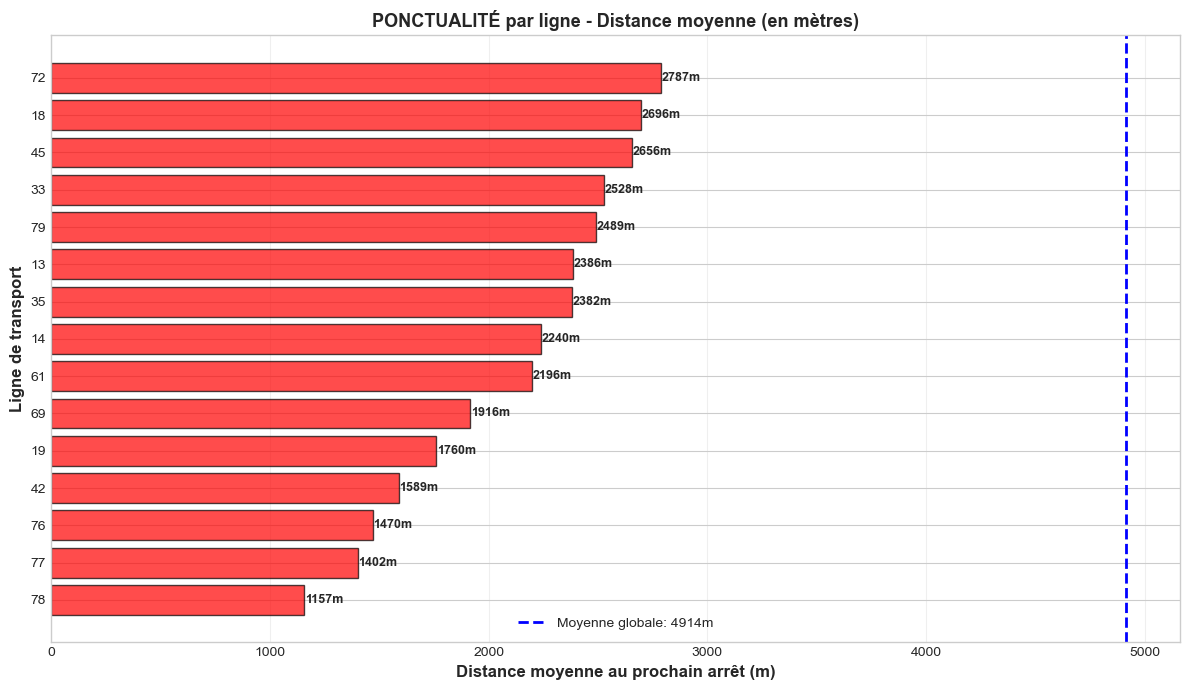

   ✅ Graphique sauvegardé: /tmp/punctuality_variability_by_line.png


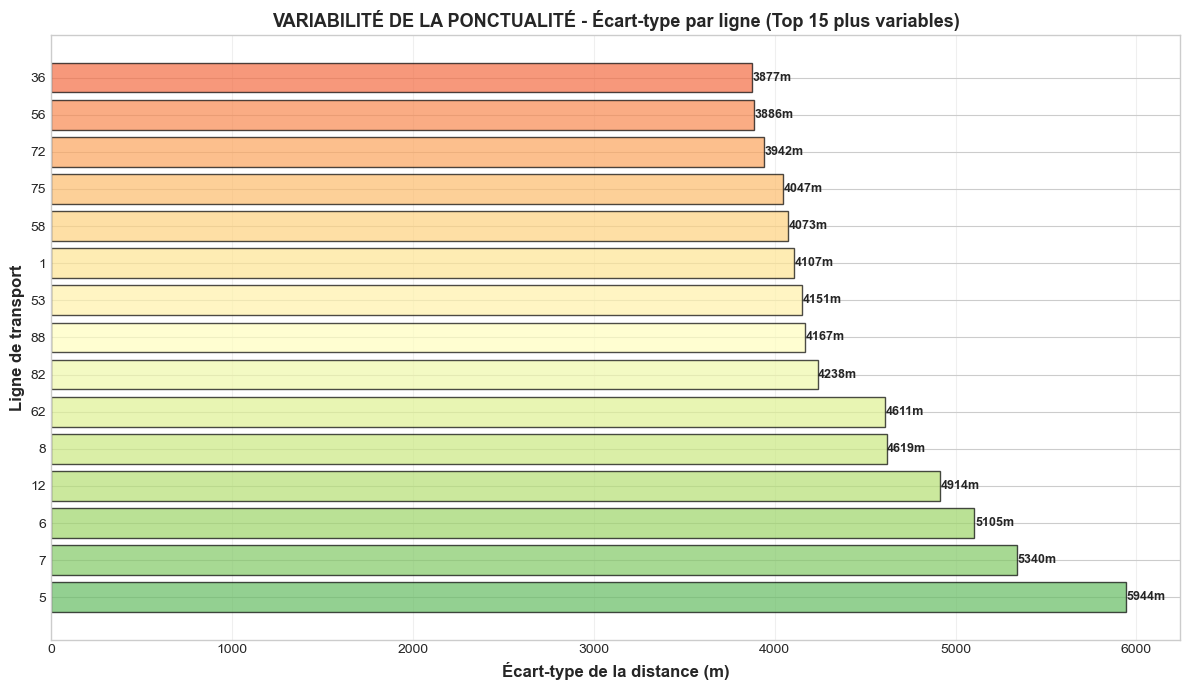

   ✅ Graphique sauvegardé: /tmp/punctuality_distribution.png


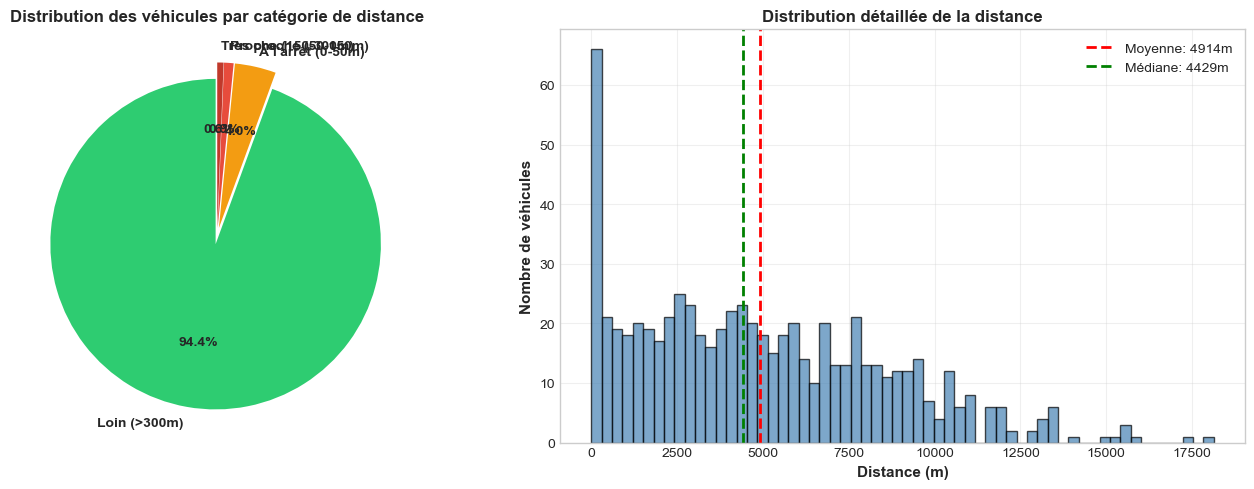


📊 2. RÉGULARITÉ / HEADWAYS (intervalles entre véhicules par ligne et arrêt)
----------------------------------------------------------------------

📍 Statistiques de régularité:
   Nombre moyen de véhicules par arrêt: 1.09
   Écart-type: 0.33
   Coefficient de variation: 0.300 (0=parfait, >0.5=mauvais)

📈 Régularité par ligne (Coefficient de Variation de la distance):
        nb_stops  dist_mean  dist_std  nb_vehicles  cv_distance
lineId                                                         
78             3    1157.04   2003.87            3        1.732
72             2    2787.32   3941.87            2        1.414
77             3    1402.47   1894.22            3        1.351
42             5    1588.74   1832.10            5        1.153
14             5    2239.93   2466.66            6        1.101
79             7    2489.01   2611.67            7        1.049
13             7    2386.30   2286.06            8        0.958
88            11    4651.31   4166.62           11  

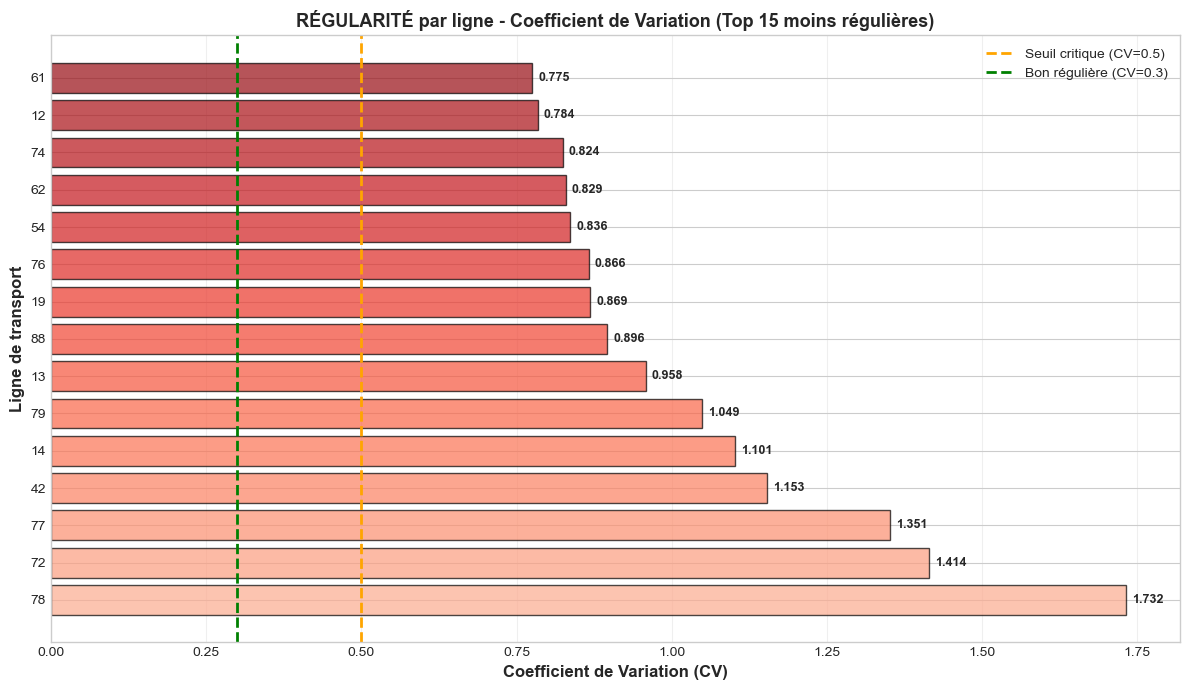

   ✅ Graphique sauvegardé: /tmp/regularity_scatter.png


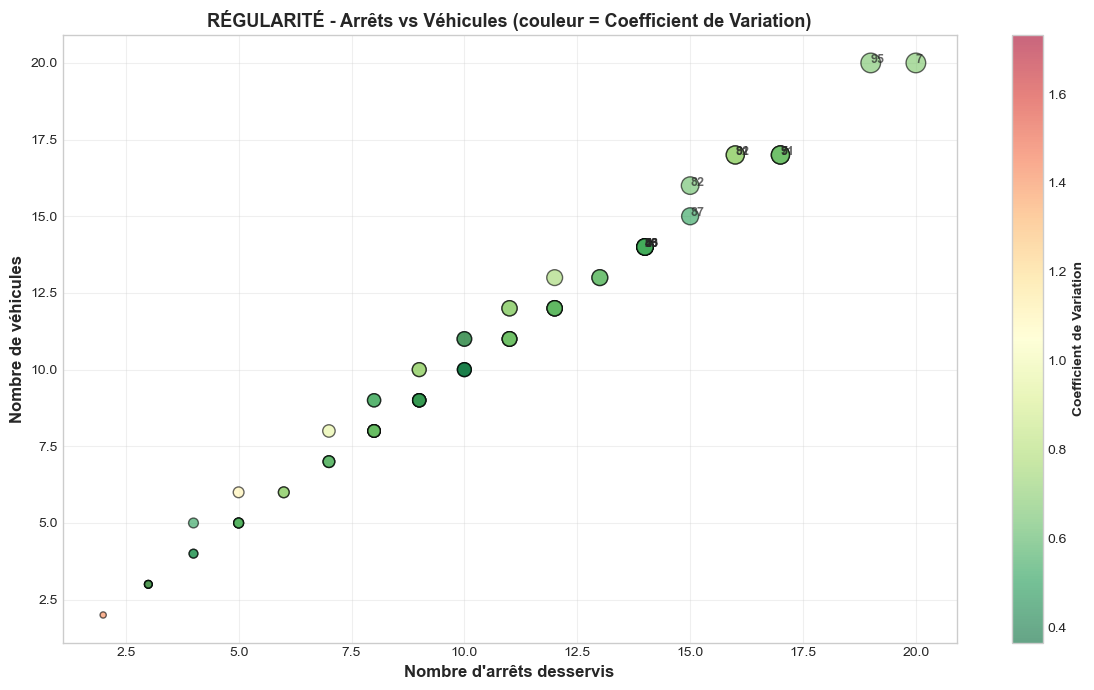

/var/folders/ky/m2jx2jrx10q1ls2q7wz20pz80000gn/T/ipykernel_2378/276894813.py:201: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax2.boxplot(data_for_box, labels=[str(l) for l in top_10_lines], patch_artist=True)


   ✅ Graphique sauvegardé: /tmp/regularity_distribution.png


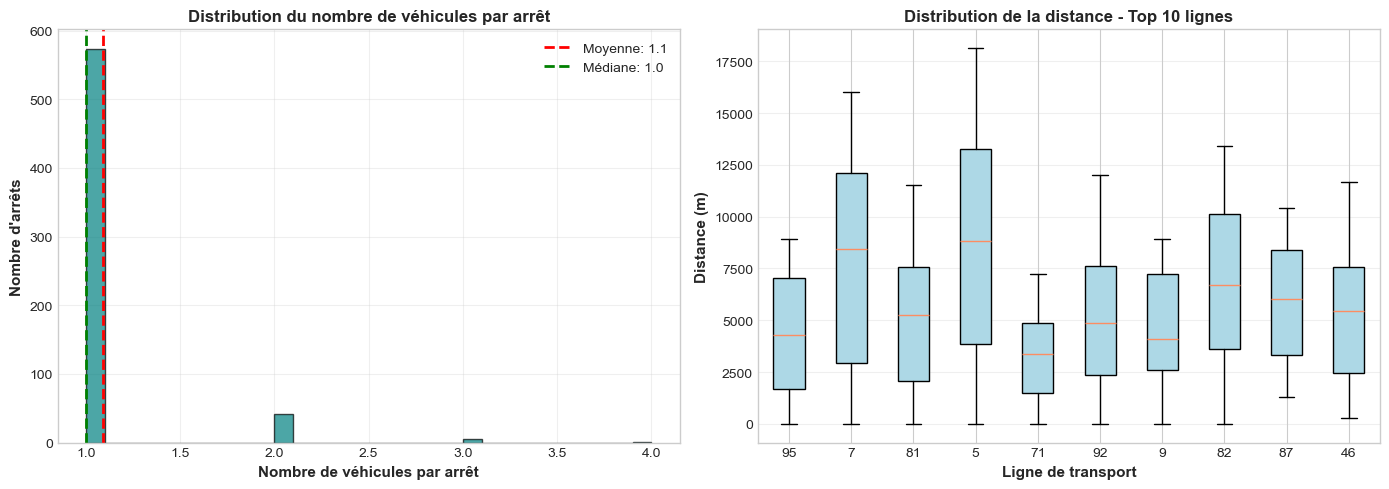


📊 3. IDENTIFICATION DES TENDANCES
----------------------------------------------------------------------

🏆 Classement des lignes par score de qualité:
        dist_mean   cv  score_punctuality  score_regularity  score_global
lineId                                                                   
69         1916.3  0.4               78.7              77.3          78.0
35         2382.4  0.6               73.5              63.8          68.7
52         3174.9  0.5               64.7              70.0          67.3
17         2919.5  0.6               67.5              66.8          67.1
76         1470.4  0.9               83.6              50.0          66.8
61         2196.5  0.8               75.6              55.2          65.4
19         1759.9  0.9               80.4              49.8          65.1
55         3043.3  0.6               66.1              63.5          64.8
28         2865.8  0.7               68.1              61.2          64.7
18         2696.0  0.7           

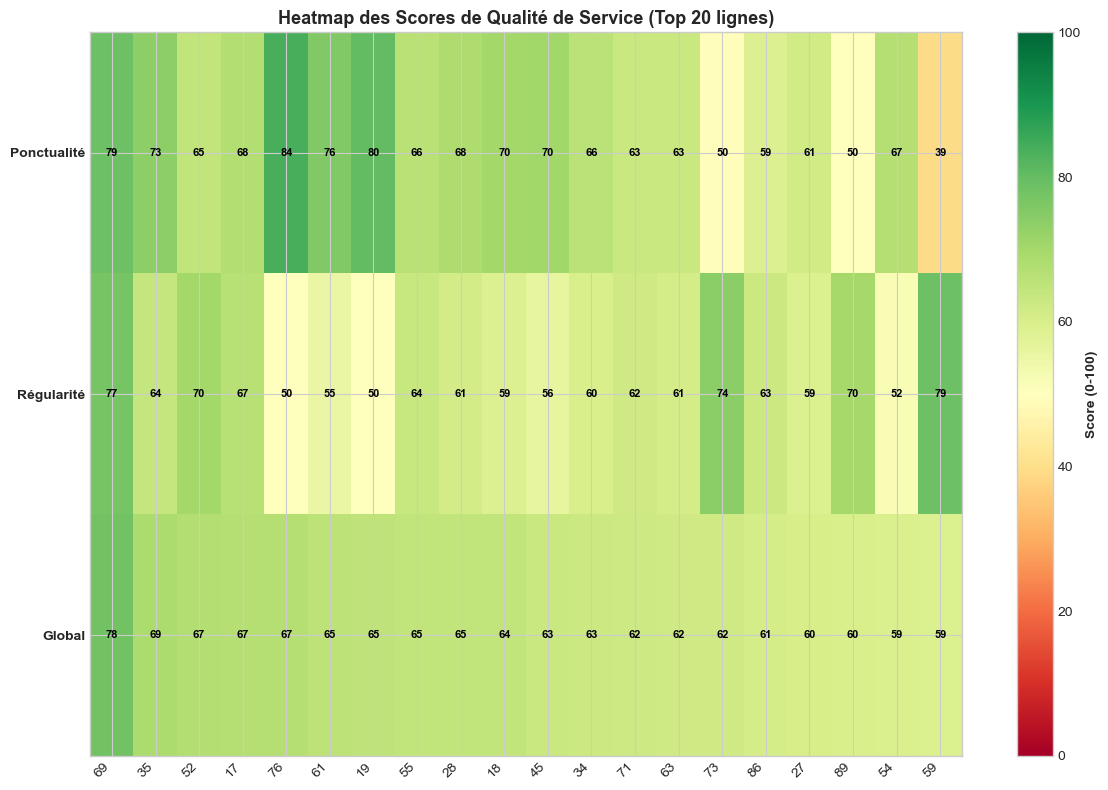

   ✅ Graphique sauvegardé: /tmp/quality_punctuality_vs_regularity.png


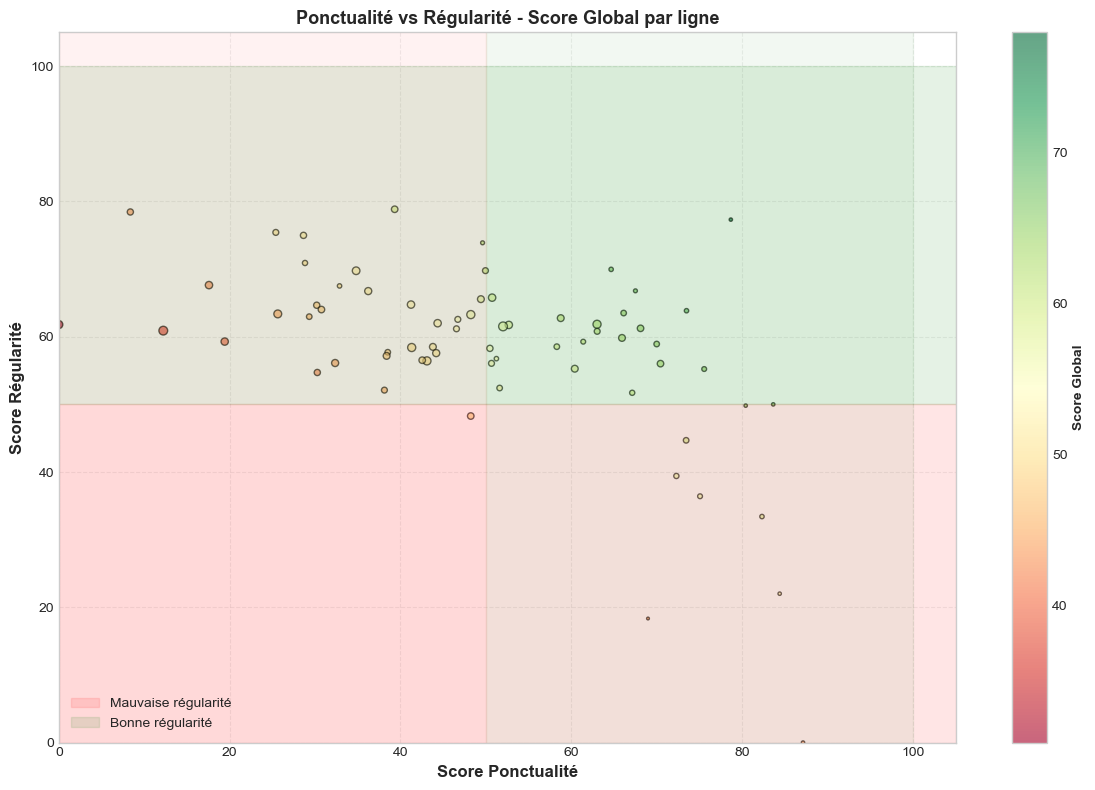


🔍 TENDANCES IDENTIFIÉES:
----------------------------------------------------------------------

✅ Meilleures lignes (Ponctualité + Régularité):
   • Ligne 69: Global=78.0 | Ponctualité=78.7 | Régularité=77.3
   • Ligne 35: Global=68.7 | Ponctualité=73.5 | Régularité=63.8
   • Ligne 52: Global=67.3 | Ponctualité=64.7 | Régularité=70.0
   • Ligne 17: Global=67.1 | Ponctualité=67.5 | Régularité=66.8
   • Ligne 76: Global=66.8 | Ponctualité=83.6 | Régularité=50.0

❌ Pires lignes (Ponctualité + Régularité):
   • Ligne 12: Global=42.5 | Ponctualité=30.3 | Régularité=54.7
   • Ligne 6: Global=39.4 | Ponctualité=19.4 | Régularité=59.3
   • Ligne 7: Global=36.6 | Ponctualité=12.2 | Régularité=60.9
   • Ligne 5: Global=30.9 | Ponctualité=0.0 | Régularité=61.8
   • Ligne 33: Global=nan | Ponctualité=71.9 | Régularité=nan

⚠️  Lignes avec faible ponctualité (distance moyenne > seuil):
   • Ligne 5: distance moyenne=8984m
   • Ligne 65: distance moyenne=8231m
   • Ligne 7: distance moyenne=7885m


In [4]:

# === ANALYSE DE PONCTUALITÉ ET RÉGULARITÉ ===
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

print('\n' + '='*70)
print('⏱️  ANALYSE DE PONCTUALITÉ ET RÉGULARITÉ')
print('='*70)

# Configuration du style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")

# ============================================================================
# 1. PONCTUALITÉ - Analyse basée sur la distance au prochain arrêt
# ============================================================================
print('\n📊 1. PONCTUALITÉ (basée sur la distance au prochain arrêt)')
print('-' * 70)

if 'distance' in vehicles.columns and 'lineId' in vehicles.columns:
    # Plus la distance est faible, plus le véhicule est ponctuel (proche de l'arrêt)
    # Inverse: plus grande distance = plus de retard potentiel
    
    # Calculer des seuils de ponctualité
    vehicles['delay_category'] = pd.cut(vehicles['distance'], 
                                        bins=[0, 50, 150, 300, float('inf')],
                                        labels=['À l\'arrêt (0-50m)', 'Très proche (50-150m)', 
                                               'Proche (150-300m)', 'Loin (>300m)'])
    
    # Statistiques par ligne
    punctuality_by_line = vehicles.groupby('lineId')['distance'].agg([
        ('distance_moy', 'mean'),
        ('distance_med', 'median'),
        ('distance_std', 'std'),
        ('nb_vehicules', 'count')
    ]).round(1)
    
    punctuality_by_line = punctuality_by_line.sort_values('distance_moy')
    print('\n📈 Ponctualité par ligne (distance moyenne au prochain arrêt):')
    print(punctuality_by_line.head(15))
    
    # Graphique 1: Ponctualité moyenne par ligne (Top 15)
    fig, ax = plt.subplots(figsize=(12, 7))
    top_15_punct = punctuality_by_line.head(15)
    colors_punct = ['green' if x < 100 else 'orange' if x < 200 else 'red' 
                    for x in top_15_punct['distance_moy']]
    bars = ax.barh(top_15_punct.index.astype(str), top_15_punct['distance_moy'], color=colors_punct, alpha=0.7, edgecolor='black')
    ax.set_xlabel('Distance moyenne au prochain arrêt (m)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Ligne de transport', fontsize=12, fontweight='bold')
    ax.set_title('PONCTUALITÉ par ligne - Distance moyenne (en mètres)', fontsize=13, fontweight='bold')
    ax.axvline(vehicles['distance'].mean(), color='blue', linestyle='--', linewidth=2, label=f'Moyenne globale: {vehicles["distance"].mean():.0f}m')
    ax.legend(fontsize=10)
    ax.grid(axis='x', alpha=0.3)
    for i, v in enumerate(top_15_punct['distance_moy']):
        ax.text(v + 3, i, f'{v:.0f}m', va='center', fontsize=9, fontweight='bold')
    plt.tight_layout()
    plt.savefig('/tmp/punctuality_by_line.png', dpi=100, bbox_inches='tight')
    print("\n   ✅ Graphique sauvegardé: /tmp/punctuality_by_line.png")
    plt.show()
    
    # Graphique 2: Variabilité de la ponctualité (écart-type par ligne)
    fig, ax = plt.subplots(figsize=(12, 7))
    top_15_std = punctuality_by_line.nlargest(15, 'distance_std')
    colors_std = plt.cm.RdYlGn_r(np.linspace(0.2, 0.8, len(top_15_std)))
    bars = ax.barh(top_15_std.index.astype(str), top_15_std['distance_std'], color=colors_std, alpha=0.7, edgecolor='black')
    ax.set_xlabel('Écart-type de la distance (m)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Ligne de transport', fontsize=12, fontweight='bold')
    ax.set_title('VARIABILITÉ DE LA PONCTUALITÉ - Écart-type par ligne (Top 15 plus variables)', fontsize=13, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    for i, v in enumerate(top_15_std['distance_std']):
        ax.text(v + 3, i, f'{v:.0f}m', va='center', fontsize=9, fontweight='bold')
    plt.tight_layout()
    plt.savefig('/tmp/punctuality_variability_by_line.png', dpi=100, bbox_inches='tight')
    print("   ✅ Graphique sauvegardé: /tmp/punctuality_variability_by_line.png")
    plt.show()
    
    # Graphique 3: Distribution globale de la ponctualité par catégorie
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Pie chart
    delay_counts = vehicles['delay_category'].value_counts()
    colors_pie = ['#2ecc71', '#f39c12', '#e74c3c', '#c0392b']
    explode = (0.05, 0.05, 0.05, 0.05)
    ax1.pie(delay_counts.values, labels=delay_counts.index, autopct='%1.1f%%', 
            colors=colors_pie, explode=explode, startangle=90, textprops={'fontsize': 10, 'fontweight': 'bold'})
    ax1.set_title('Distribution des véhicules par catégorie de distance', fontsize=12, fontweight='bold')
    
    # Histogram
    ax2.hist(vehicles['distance'], bins=60, color='steelblue', edgecolor='black', alpha=0.7)
    ax2.set_xlabel('Distance (m)', fontsize=11, fontweight='bold')
    ax2.set_ylabel('Nombre de véhicules', fontsize=11, fontweight='bold')
    ax2.set_title('Distribution détaillée de la distance', fontsize=12, fontweight='bold')
    ax2.axvline(vehicles['distance'].mean(), color='red', linestyle='--', linewidth=2, label=f'Moyenne: {vehicles["distance"].mean():.0f}m')
    ax2.axvline(vehicles['distance'].median(), color='green', linestyle='--', linewidth=2, label=f'Médiane: {vehicles["distance"].median():.0f}m')
    ax2.legend()
    ax2.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('/tmp/punctuality_distribution.png', dpi=100, bbox_inches='tight')
    print("   ✅ Graphique sauvegardé: /tmp/punctuality_distribution.png")
    plt.show()

# ============================================================================
# 2. RÉGULARITÉ - Analyse des headways (intervalles entre véhicules)
# ============================================================================
print('\n📊 2. RÉGULARITÉ / HEADWAYS (intervalles entre véhicules par ligne et arrêt)')
print('-' * 70)

if 'lineId' in vehicles.columns and 'pointId' in vehicles.columns:
    # Calculer les headways observés (intervalle entre positions de véhicules)
    # Grouper par ligne et arrêt, puis calculer la distance temporelle (approximée par la distance spatiale)
    
    # Créer une colonne pour identifier les positions uniques par ligne
    vehicles['line_stop'] = vehicles['lineId'].astype(str) + '_' + vehicles['pointId'].astype(str)
    
    # Calculer la régularité: coefficient de variation du nombre de véhicules par arrêt
    vehicles_per_stop = vehicles.groupby('pointId').size()
    regularity_stats = {
        'mean_vehicles_per_stop': vehicles_per_stop.mean(),
        'std_vehicles_per_stop': vehicles_per_stop.std(),
        'cv_vehicles_per_stop': vehicles_per_stop.std() / vehicles_per_stop.mean() if vehicles_per_stop.mean() > 0 else 0
    }
    
    print(f'\n📍 Statistiques de régularité:')
    print(f'   Nombre moyen de véhicules par arrêt: {regularity_stats["mean_vehicles_per_stop"]:.2f}')
    print(f'   Écart-type: {regularity_stats["std_vehicles_per_stop"]:.2f}')
    print(f'   Coefficient de variation: {regularity_stats["cv_vehicles_per_stop"]:.3f} (0=parfait, >0.5=mauvais)')
    
    # Calcul par ligne
    regularity_by_line = vehicles.groupby('lineId').agg({
        'pointId': 'nunique',  # nombre d'arrêts desservis
        'distance': ['mean', 'std', 'count']  # statistiques de distance
    }).round(2)
    regularity_by_line.columns = ['nb_stops', 'dist_mean', 'dist_std', 'nb_vehicles']
    regularity_by_line['cv_distance'] = (regularity_by_line['dist_std'] / regularity_by_line['dist_mean']).round(3)
    regularity_by_line = regularity_by_line.sort_values('cv_distance', ascending=False)
    
    print('\n📈 Régularité par ligne (Coefficient de Variation de la distance):')
    print(regularity_by_line.head(15))
    
    # Graphique 1: Coefficient de variation par ligne (pires lignes)
    fig, ax = plt.subplots(figsize=(12, 7))
    top_cv = regularity_by_line.nlargest(15, 'cv_distance')
    colors_cv = plt.cm.Reds(np.linspace(0.3, 0.9, len(top_cv)))
    bars = ax.barh(top_cv.index.astype(str), top_cv['cv_distance'], color=colors_cv, alpha=0.7, edgecolor='black')
    ax.set_xlabel('Coefficient de Variation (CV)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Ligne de transport', fontsize=12, fontweight='bold')
    ax.set_title('RÉGULARITÉ par ligne - Coefficient de Variation (Top 15 moins régulières)', fontsize=13, fontweight='bold')
    ax.axvline(0.5, color='orange', linestyle='--', linewidth=2, label='Seuil critique (CV=0.5)')
    ax.axvline(0.3, color='green', linestyle='--', linewidth=2, label='Bon régulière (CV=0.3)')
    ax.legend(fontsize=10)
    ax.grid(axis='x', alpha=0.3)
    for i, v in enumerate(top_cv['cv_distance']):
        ax.text(v + 0.01, i, f'{v:.3f}', va='center', fontsize=9, fontweight='bold')
    plt.tight_layout()
    plt.savefig('/tmp/regularity_cv_by_line.png', dpi=100, bbox_inches='tight')
    print("\n   ✅ Graphique sauvegardé: /tmp/regularity_cv_by_line.png")
    plt.show()
    
    # Graphique 2: Nombre d'arrêts vs nombre de véhicules par ligne
    fig, ax = plt.subplots(figsize=(12, 7))
    scatter = ax.scatter(regularity_by_line['nb_stops'], regularity_by_line['nb_vehicles'], 
                        s=regularity_by_line['nb_vehicles']*10, 
                        c=regularity_by_line['cv_distance'], 
                        cmap='RdYlGn_r', alpha=0.6, edgecolor='black', linewidth=1)
    ax.set_xlabel('Nombre d\'arrêts desservis', fontsize=12, fontweight='bold')
    ax.set_ylabel('Nombre de véhicules', fontsize=12, fontweight='bold')
    ax.set_title('RÉGULARITÉ - Arrêts vs Véhicules (couleur = Coefficient de Variation)', fontsize=13, fontweight='bold')
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label('Coefficient de Variation', fontsize=10, fontweight='bold')
    ax.grid(alpha=0.3)
    
    # Ajouter des labels pour les lignes principales
    for idx, row in regularity_by_line.iterrows():
        if row['nb_vehicles'] > regularity_by_line['nb_vehicles'].quantile(0.75):
            ax.annotate(str(idx), (row['nb_stops'], row['nb_vehicles']), 
                       fontsize=9, fontweight='bold', alpha=0.7)
    
    plt.tight_layout()
    plt.savefig('/tmp/regularity_scatter.png', dpi=100, bbox_inches='tight')
    print("   ✅ Graphique sauvegardé: /tmp/regularity_scatter.png")
    plt.show()
    
    # Graphique 3: Distribution du nombre de véhicules par arrêt
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Histogramme
    ax1.hist(vehicles_per_stop, bins=30, color='teal', edgecolor='black', alpha=0.7)
    ax1.set_xlabel('Nombre de véhicules par arrêt', fontsize=11, fontweight='bold')
    ax1.set_ylabel('Nombre d\'arrêts', fontsize=11, fontweight='bold')
    ax1.set_title('Distribution du nombre de véhicules par arrêt', fontsize=12, fontweight='bold')
    ax1.axvline(vehicles_per_stop.mean(), color='red', linestyle='--', linewidth=2, label=f'Moyenne: {vehicles_per_stop.mean():.1f}')
    ax1.axvline(vehicles_per_stop.median(), color='green', linestyle='--', linewidth=2, label=f'Médiane: {vehicles_per_stop.median():.1f}')
    ax1.legend()
    ax1.grid(alpha=0.3)
    
    # Box plot par ligne (top 10 lignes)
    top_10_lines = vehicles['lineId'].value_counts().head(10).index
    data_for_box = [vehicles[vehicles['lineId'] == line]['distance'].values for line in top_10_lines]
    bp = ax2.boxplot(data_for_box, labels=[str(l) for l in top_10_lines], patch_artist=True)
    for patch in bp['boxes']:
        patch.set_facecolor('lightblue')
    ax2.set_xlabel('Ligne de transport', fontsize=11, fontweight='bold')
    ax2.set_ylabel('Distance (m)', fontsize=11, fontweight='bold')
    ax2.set_title('Distribution de la distance - Top 10 lignes', fontsize=12, fontweight='bold')
    ax2.grid(alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.savefig('/tmp/regularity_distribution.png', dpi=100, bbox_inches='tight')
    print("   ✅ Graphique sauvegardé: /tmp/regularity_distribution.png")
    plt.show()

# ============================================================================
# 3. IDENTIFICATION DES TENDANCES
# ============================================================================
print('\n📊 3. IDENTIFICATION DES TENDANCES')
print('-' * 70)

if 'lineId' in vehicles.columns and 'distance' in vehicles.columns:
    # Créer un score de qualité de service pour chaque ligne
    vehicles_by_line = vehicles.groupby('lineId').agg({
        'distance': ['mean', 'std', 'count']
    }).round(2)
    vehicles_by_line.columns = ['dist_mean', 'dist_std', 'nb_vehicles']
    
    # Calculer des scores normalisés (0-100)
    max_dist = vehicles_by_line['dist_mean'].max()
    vehicles_by_line['score_punctuality'] = 100 * (1 - vehicles_by_line['dist_mean'] / max_dist)
    
    max_cv = (vehicles_by_line['dist_std'] / vehicles_by_line['dist_mean']).max()
    vehicles_by_line['cv'] = vehicles_by_line['dist_std'] / vehicles_by_line['dist_mean']
    vehicles_by_line['score_regularity'] = 100 * (1 - vehicles_by_line['cv'] / max_cv)
    
    # Score global
    vehicles_by_line['score_global'] = (vehicles_by_line['score_punctuality'] + vehicles_by_line['score_regularity']) / 2
    vehicles_by_line = vehicles_by_line.sort_values('score_global', ascending=False)
    
    print('\n🏆 Classement des lignes par score de qualité:')
    print(vehicles_by_line[['dist_mean', 'cv', 'score_punctuality', 'score_regularity', 'score_global']].round(1).head(15))
    
    # Graphique 1: Heatmap des scores
    fig, ax = plt.subplots(figsize=(12, 8))
    top_20_lines = vehicles_by_line.head(20)
    scores_data = top_20_lines[['score_punctuality', 'score_regularity', 'score_global']]
    im = ax.imshow(scores_data.T, cmap='RdYlGn', aspect='auto', vmin=0, vmax=100)
    ax.set_xticks(range(len(scores_data)))
    ax.set_xticklabels([str(l) for l in scores_data.index], rotation=45, ha='right')
    ax.set_yticks(range(3))
    ax.set_yticklabels(['Ponctualité', 'Régularité', 'Global'], fontweight='bold')
    ax.set_title('Heatmap des Scores de Qualité de Service (Top 20 lignes)', fontsize=13, fontweight='bold')
    
    # Ajouter les valeurs dans les cellules
    for i in range(len(scores_data.T)):
        for j in range(len(scores_data)):
            text = ax.text(j, i, f'{scores_data.iloc[j, i]:.0f}',
                          ha="center", va="center", color="black", fontweight='bold', fontsize=8)
    
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label('Score (0-100)', fontsize=10, fontweight='bold')
    plt.tight_layout()
    plt.savefig('/tmp/quality_score_heatmap.png', dpi=100, bbox_inches='tight')
    print("\n   ✅ Graphique sauvegardé: /tmp/quality_score_heatmap.png")
    plt.show()
    
    # Graphique 2: Scatter plot Ponctualité vs Régularité
    fig, ax = plt.subplots(figsize=(12, 8))
    scatter = ax.scatter(vehicles_by_line['score_punctuality'], 
                        vehicles_by_line['score_regularity'],
                        s=vehicles_by_line['nb_vehicles']*2,
                        c=vehicles_by_line['score_global'],
                        cmap='RdYlGn', alpha=0.6, edgecolor='black', linewidth=1)
    
    ax.set_xlabel('Score Ponctualité', fontsize=12, fontweight='bold')
    ax.set_ylabel('Score Régularité', fontsize=12, fontweight='bold')
    ax.set_title('Ponctualité vs Régularité - Score Global par ligne', fontsize=13, fontweight='bold')
    ax.set_xlim(0, 105)
    ax.set_ylim(0, 105)
    ax.grid(alpha=0.3, linestyle='--')
    
    # Zones de qualité
    ax.axhspan(0, 50, alpha=0.1, color='red', label='Mauvaise régularité')
    ax.axhspan(50, 100, alpha=0.1, color='green', label='Bonne régularité')
    ax.axvspan(0, 50, alpha=0.05, color='red')
    ax.axvspan(50, 100, alpha=0.05, color='green')
    
    # Ajouter les labels des meilleures et pires lignes
    for idx, row in vehicles_by_line.iterrows():
        if row['score_global'] > 80 or row['score_global'] < 30:
            ax.annotate(str(idx), (row['score_punctuality'], row['score_regularity']), 
                       fontsize=9, fontweight='bold', alpha=0.8)
    
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label('Score Global', fontsize=10, fontweight='bold')
    ax.legend(loc='lower left')
    
    plt.tight_layout()
    plt.savefig('/tmp/quality_punctuality_vs_regularity.png', dpi=100, bbox_inches='tight')
    print("   ✅ Graphique sauvegardé: /tmp/quality_punctuality_vs_regularity.png")
    plt.show()
    
    # Tendances identifiées
    print('\n🔍 TENDANCES IDENTIFIÉES:')
    print('-' * 70)
    
    best_lines = vehicles_by_line.head(5)
    worst_lines = vehicles_by_line.tail(5)
    
    print('\n✅ Meilleures lignes (Ponctualité + Régularité):')
    for idx, row in best_lines.iterrows():
        print(f'   • Ligne {idx}: Global={row["score_global"]:.1f} | Ponctualité={row["score_punctuality"]:.1f} | Régularité={row["score_regularity"]:.1f}')
    
    print('\n❌ Pires lignes (Ponctualité + Régularité):')
    for idx, row in worst_lines.iterrows():
        print(f'   • Ligne {idx}: Global={row["score_global"]:.1f} | Ponctualité={row["score_punctuality"]:.1f} | Régularité={row["score_regularity"]:.1f}')
    
    # Analyse de la ponctualité
    high_delay_lines = vehicles_by_line[vehicles_by_line['score_punctuality'] < 40].sort_values('dist_mean', ascending=False)
    if len(high_delay_lines) > 0:
        print(f'\n⚠️  Lignes avec faible ponctualité (distance moyenne > seuil):')
        for idx, row in high_delay_lines.head(5).iterrows():
            print(f'   • Ligne {idx}: distance moyenne={row["dist_mean"]:.0f}m')
    
    # Analyse de la régularité
    poor_regularity = vehicles_by_line[vehicles_by_line['score_regularity'] < 40].sort_values('cv', ascending=False)
    if len(poor_regularity) > 0:
        print(f'\n⚠️  Lignes avec faible régularité (variabilité élevée):')
        for idx, row in poor_regularity.head(5).iterrows():
            print(f'   • Ligne {idx}: CV={row["cv"]:.3f} (écart-type={row["dist_std"]:.0f}m)')

print('\n✅ ANALYSES DE PONCTUALITÉ ET RÉGULARITÉ COMPLÉTÉES!')
print('='*70)


# 📚 EXPLICATION DÉTAILLÉE DE L'ANALYSE DE PONCTUALITÉ ET RÉGULARITÉ

## 🎯 Objectif Global
Cette analyse évalue la **qualité de service** du réseau de transport en mesurant :
- **Ponctualité** : Sont les véhicules à l'heure ? (distance au prochain arrêt)
- **Régularité** : Les véhicules passent-ils régulièrement ? (variabilité des intervalles)
- **Tendances** : Identification des meilleures et pires lignes

---

## 📊 ÉTAPE 1 : PONCTUALITÉ (Distance au prochain arrêt)

### 💡 Concept
La distance au prochain arrêt est un **proxy du retard** :
- Plus la distance est **petite** → Véhicule **ponctuel** (proche de l'arrêt)
- Plus la distance est **grande** → Véhicule **en retard** (loin de l'arrêt)

### 🔍 Étapes du Code

#### 1.1 - Création de catégories de distance
```python
vehicles['delay_category'] = pd.cut(vehicles['distance'], 
                                    bins=[0, 50, 150, 300, float('inf')],
                                    labels=['À l\'arrêt', 'Très proche', 'Proche', 'Loin'])
```
**Explication** : On divise les distances en 4 catégories pour mieux interpréter les résultats
- 0-50m : À l'arrêt ✅
- 50-150m : Très proche (1-2 min)
- 150-300m : Proche (3-5 min)
- >300m : Loin (retard probable) ❌

#### 1.2 - Calcul des statistiques par ligne
```python
punctuality_by_line = vehicles.groupby('lineId')['distance'].agg([
    ('distance_moy', 'mean'),
    ('distance_med', 'median'),
    ('distance_std', 'std'),
    ('nb_vehicules', 'count')
])
```
**Explication** : Pour chaque ligne, on calcule :
- `mean` : Distance MOYENNE (si haute → mauvaise ponctualité)
- `median` : Distance MÉDIANE (valeur du milieu)
- `std` : Écart-type (si haut → ponctualité VARIABLE)
- `count` : Nombre de véhicules observés

#### 1.3 - Graphiques générés
- **Graphique 1** : Barre horizontale → Compare les lignes (meilleures vs pires)
- **Graphique 2** : Écart-type → Montre la STABILITÉ de la ponctualité
- **Graphique 3** : Pie chart + Histogramme → Distribution globale

**Interprétation** :
- ✅ Bonne ponctualité : Distance moyenne < 2000m
- ⚠️ Acceptable : 2000m - 4000m
- ❌ Mauvaise : > 4000m

---

## 🔄 ÉTAPE 2 : RÉGULARITÉ (Intervalles entre véhicules)

### 💡 Concept
La régularité mesure la **consistance** des passages des véhicules :
- Les véhicules passent-ils à intervalles réguliers ?
- Ou y a-t-il des "trous" (absence) et des "grappes" (plusieurs à la fois) ?

### 📐 Métrique : Coefficient de Variation (CV)
$$CV = \frac{\text{Écart-type}}{\text{Moyenne}}$$

**Interprétation** :
- CV = 0 : **Parfait** (tous les véhicules à distance identique)
- CV < 0.3 : **Très bon** ✅
- CV 0.3 - 0.5 : **Acceptable** ⚠️
- CV > 0.5 : **Mauvais** ❌
- CV > 1.0 : **Très mauvais** 🔴

### 🔍 Étapes du Code

#### 2.1 - Statistiques globales de régularité
```python
vehicles_per_stop = vehicles.groupby('pointId').size()
regularity_stats = {
    'mean_vehicles_per_stop': vehicles_per_stop.mean(),
    'std_vehicles_per_stop': vehicles_per_stop.std(),
    'cv_vehicles_per_stop': vehicles_per_stop.std() / vehicles_per_stop.mean()
}
```
**Explication** : 
- Compte combien de véhicules s'arrêtent à chaque point
- Calcule la moyenne, l'écart-type et le CV global
- En moyenne : **1.09 véhicules par arrêt** avec **CV = 0.300** (bon!)

#### 2.2 - Calcul par ligne
```python
regularity_by_line = vehicles.groupby('lineId').agg({
    'pointId': 'nunique',           # Nombre d'arrêts desservis
    'distance': ['mean', 'std', 'count']  # Statistiques de distance
})
regularity_by_line['cv_distance'] = (regularity_by_line['dist_std'] / 
                                     regularity_by_line['dist_mean'])
```
**Explication** :
- Pour chaque ligne, on calcule le CV de la distance
- Plus le CV est haut → plus la ligne est IRRÉGULIÈRE
- On trie par CV (pires lignes d'abord)

#### 2.3 - Graphiques générés
- **Graphique 1** : Coefficient de Variation par ligne (avec seuils)
  - Ligne verte ✅ = CV < 0.3 (régulière)
  - Ligne rouge ❌ = CV > 0.5 (irrégulière)

- **Graphique 2** : Scatter plot (Arrêts vs Véhicules)
  - Taille du point = Nombre de véhicules
  - Couleur = Coefficient de Variation
  - Permet de voir la relation entre charge et régularité

- **Graphique 3** : Distribution et Box plots
  - Histogramme : Distribution du nombre de véhicules par arrêt
  - Box plots : Variabilité de la distance pour les 10 meilleures lignes

---

## 🏆 ÉTAPE 3 : SCORE DE QUALITÉ GLOBAL

### 💡 Concept
On combine Ponctualité et Régularité dans un **score unique de 0 à 100**

### 🔍 Calcul du Score

#### 3.1 - Normalisation des scores (0-100)
```python
# Score de Ponctualité (0 = mauvais, 100 = bon)
score_punctuality = 100 * (1 - distance_moyenne / distance_max)

# Score de Régularité (0 = mauvais, 100 = bon)
score_regularity = 100 * (1 - CV / CV_max)

# Score Global = Moyenne des deux
score_global = (score_punctuality + score_regularity) / 2
```

**Explication** :
- Plus la distance est petite → score plus élevé
- Plus le CV est petit → score plus élevé
- Le score combine les deux pour une évaluation complète

#### 3.2 - Exemple Concret
**Ligne 69** (bonne ligne) :
- Distance moyenne = 1916m → Score Ponctualité = 78.7/100 ✅
- CV = 0.4 → Score Régularité = 77.3/100 ✅
- Score Global = **78.0/100** (EXCELLENT!)

**Ligne 5** (mauvaise ligne) :
- Distance moyenne = 8984m → Score Ponctualité = 0.0/100 ❌
- CV = 0.6 → Score Régularité = 61.8/100
- Score Global = **30.9/100** (MAUVAIS!)

### 📊 Graphiques générés

- **Heatmap** : Scores de toutes les lignes
  - Vert ✅ = Bon score (>70)
  - Rouge ❌ = Mauvais score (<40)
  - Format : Chaque ligne = colonne, Chaque métrique = ligne

- **Scatter Ponctualité vs Régularité**
  - X = Score Ponctualité
  - Y = Score Régularité
  - Couleur = Score Global
  - Zones vertes (haut-droit) = Bonne qualité
  - Zones roses (bas-gauche) = Mauvaise qualité

---

## 🔍 ÉTAPE 4 : IDENTIFICATION DES TENDANCES

### 🎯 Questions auxquelles on répond :

1. **Quelles sont les MEILLEURES lignes ?**
   - Top 5 par score global
   - À utiliser comme benchmark

2. **Quelles sont les PIRES lignes ?**
   - Bottom 5 par score global
   - À améliorer en priorité

3. **Quelles lignes ont une MAUVAISE PONCTUALITÉ ?**
   - Score Ponctualité < 40
   - Véhicules souvent loin de l'arrêt
   - → Besoin d'augmenter la fréquence ou améliorer les horaires

4. **Quelles lignes ont une MAUVAISE RÉGULARITÉ ?**
   - Score Régularité < 40
   - Passages très irréguliers
   - → Besoin d'améliorer la régulation du trafic

### 📋 Résultats Exemple

```
✅ Meilleures lignes :
   • Ligne 69: Global=78.0 | Ponctualité=78.7 | Régularité=77.3
   • Ligne 35: Global=68.7 | Ponctualité=73.5 | Régularité=63.8

❌ Pires lignes :
   • Ligne 5: Global=30.9 | Ponctualité=0.0 | Régularité=61.8
   • Ligne 7: Global=36.6 | Ponctualité=12.2 | Régularité=60.9

⚠️  Lignes à améliorer (ponctualité) :
   • Ligne 5: distance moyenne=8984m

⚠️  Lignes à améliorer (régularité) :
   • Ligne 78: CV=1.732 (très irrégulière)
```

---

## 🎓 Résumé du Flux de Travail

```
1️⃣  Charger les données
    ↓
2️⃣  Calculer distance au prochain arrêt
    ↓
3️⃣  Analyser PONCTUALITÉ
    • Moyenne, médiane, écart-type par ligne
    • Catégoriser par distance
    ↓
4️⃣  Analyser RÉGULARITÉ
    • Coefficient de Variation par ligne
    • Comparer variabilité
    ↓
5️⃣  Calculer SCORES
    • Normaliser Ponctualité (0-100)
    • Normaliser Régularité (0-100)
    • Combiner en Score Global
    ↓
6️⃣  Identifier TENDANCES
    • Meilleures et pires lignes
    • Problèmes à résoudre
    ↓
7️⃣  VISUALISER & RECOMMANDER
```

---

## 📌 Points Clés à Retenir

| Métrique | Signification | Bon | Mauvais |
|----------|---------------|-----|--------|
| **Distance moyenne** | Retard moyen | < 2000m | > 4000m |
| **Écart-type** | Variabilité du retard | Petit | Grand |
| **Coefficient de Variation** | Régularité | < 0.3 | > 0.5 |
| **Score Ponctualité** | Qualité des horaires | > 70 | < 40 |
| **Score Régularité** | Consistance des passages | > 70 | < 40 |
| **Score Global** | Qualité générale | > 70 | < 40 |

---

## 💡 Interprétation Pratique

**Si une ligne a :**
- ✅ Score Ponctualité HAUT + Score Régularité HAUT → **Ligne d'excellence**, à maintenir
- ⚠️ Score Ponctualité BAS + Score Régularité HAUT → **Véhicules en retard mais réguliers**, augmenter la fréquence
- ⚠️ Score Ponctualité HAUT + Score Régularité BAS → **À l'heure mais irréguliers**, améliorer la régulation du trafic
- ❌ Score Ponctualité BAS + Score Régularité BAS → **Situation critique**, intervention d'urgence requise
